<a href="https://colab.research.google.com/github/tanvi118/AISR_LAB/blob/main/Robotics_Exp_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Tanvi Vitankar, 500120658, exp-7

Comparing SGD, Adam and LBFGS.

In [1]:
import numpy as np
import pandas as pd

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

In [2]:
# Load dataset
data = load_iris()

X = data.data
y = data.target

In [3]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [4]:
# Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


solvers = ['sgd', 'adam', 'lbfgs']

results = []


for solver in solvers:

    model = MLPClassifier(
        hidden_layer_sizes=(10,),
        solver=solver,
        max_iter=3000,
        random_state=42
    )

    model.fit(X_train, y_train)

    prediction = model.predict(X_test)

    accuracy = accuracy_score(
        y_test,
        prediction
    )

    results.append([
        solver,
        accuracy
    ])


result_df = pd.DataFrame(
    results,
    columns=[
        "Learning Strategy",
        "Accuracy"
    ]
)

print(result_df)

  Learning Strategy  Accuracy
0               sgd  0.966667
1              adam  0.966667
2             lbfgs  0.900000


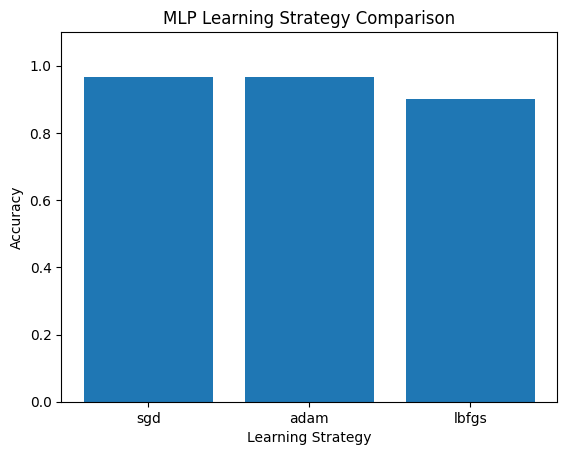

In [5]:
import matplotlib.pyplot as plt

plt.bar(
    result_df["Learning Strategy"],
    result_df["Accuracy"]
)

plt.ylim(0, 1.1)

plt.xlabel("Learning Strategy")
plt.ylabel("Accuracy")
plt.title("MLP Learning Strategy Comparison")

plt.show()